# Dans ce notebook on va comparer la trajectoire de Strava et notre Trajectoire

In [113]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
import os

# Ajoute le dossier parent au chemin Python
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from utils.correction_erreur_systematique import transformation_csv_dataframe
rayon_terre = 6371000 #rayon de la terre en m

### Lecture et exploration des données 
Dans cette partie on recupère les deux CSV correspondant qu'on explore et plote

In [124]:
own_data= transformation_csv_dataframe("/home/barry/pi_itineraire/IMU_GPS/data/test_traite_4_26_500_26.csv")
strava_data = transformation_csv_dataframe("/home/barry/pi_itineraire/Strava/4_26_250_.csv")

In [125]:
print(own_data.head())
print(strava_data.head())

      Timestamp                    UTC   Latitude  Longitude  Altitude  \
0  1.778079e+09  2026/05/06 - 14:49:43  49.384631   1.068505      80.2   
1  1.778079e+09  2026/05/06 - 14:49:43  49.384631   1.068505      80.2   
2  1.778079e+09  2026/05/06 - 14:49:43  49.384631   1.068505      80.2   
3  1.778079e+09  2026/05/06 - 14:49:43  49.384631   1.068505      80.2   
4  1.778079e+09  2026/05/06 - 14:49:43  49.384631   1.068505      80.2   

   Nb Satellites  GPS Valid   Accel X   Accel Y   Accel Z    Gyro X  \
0           17.0          1  0.706133  0.013629 -0.117665  32.61423   
1           17.0          1  0.958429 -0.083605  0.008117  32.82423   
2           17.0          1  1.095313 -0.155219 -0.063985  13.78423   
3           17.0          1  1.096045 -0.105565 -0.131695  -4.01327   
4           17.0          1  1.024797 -0.045297 -0.102293  -7.04077   

      Gyro Y     Gyro Z  
0   2.720786 -19.800049  
1   5.555786 -17.052549  
2   0.183286  -0.672549  
3 -17.404214   8.199951 

In [128]:
# Là où tu as créé own_data2 (probablement plus haut dans le notebook)
own_data2 = own_data[['Latitude', 'Longitude','UTC']].copy()
nb_ligne_onw, _ = own_data2.shape
nb_ligne_strava,_ = strava_data.shape
print("le nombre de ligne de nos données est",nb_ligne_onw)
print("le nombre de ligne de strava est ",nb_ligne_strava)

le nombre de ligne de nos données est 3080
le nombre de ligne de strava est  122


### Synchronisation des deux pour avoir le même time selon Strava
faire la moyenne de toutes les valeurs sur acquise en une acquisition de strava qui acquière à chaque seconde

In [129]:
own_data2['UTC'] = pd.to_datetime(own_data2['UTC'], format='%Y/%m/%d - %H:%M:%S', errors='coerce').copy()
own_data2 = own_data2.dropna()
dataStrava['UTC'] = pd.to_datetime(dataStrava['UTC'],format='%Y/%m/%d - %H:%M:%S', errors='coerce').copy()
dataStrava=dataStrava.dropna()

In [130]:
own_data2['UTC'] = pd.to_datetime(own_data2['UTC'])
strava_data['UTC'] = pd.to_datetime(strava_data['UTC'])

# Réindexer strava sur les timestamps de own_data par interpolation
strava_reindexed = (
    strava_data
    .set_index('UTC')
    .reindex(own_data2['UTC'])      
    .interpolate(method='time')         
    .reset_index()
    .rename(columns={'index': 'UTC'})
)

# Fusionner
df_merged = pd.concat([
    own_data2.reset_index(drop=True),
    strava_reindexed[['Latitude', 'Longitude']].rename(
        columns={'Latitude': 'Lat_strava', 'Longitude': 'Lon_strava'}
    )
], axis=1)

df_merged.head()

,Latitude,Longitude,UTC,Lat_strava,Lon_strava
0,49.384631,1.068505,2026-05-06 14:49:43,49.384605,1.068482
1,49.384631,1.068505,2026-05-06 14:49:43,49.384605,1.068482
2,49.384631,1.068505,2026-05-06 14:49:43,49.384605,1.068482
3,49.384631,1.068505,2026-05-06 14:49:43,49.384605,1.068482
4,49.384631,1.068505,2026-05-06 14:49:43,49.384605,1.068482


#### Calcul de la distane entre chaque point pour pouvoir mesuré l'erreur
on base notre mesure surle calcul de la distance entre les deux points 

In [131]:
lat1 = np.radians(df_merged['Latitude'])
lon1 = np.radians(df_merged['Longitude'])
lat2 = np.radians(df_merged['Lat_strava'])
lon2 = np.radians(df_merged['Lon_strava'])

df_merged['distance'] = rayon_terre * np.arccos(
    np.sin(lat1)*np.sin(lat2) + np.cos(lat1)*np.cos(lat2)*np.cos(lon1-lon2)
)

df_merged.head()

,Latitude,Longitude,UTC,Lat_strava,Lon_strava,distance
0,49.384631,1.068505,2026-05-06 14:49:43,49.384605,1.068482,3.281797
1,49.384631,1.068505,2026-05-06 14:49:43,49.384605,1.068482,3.281797
2,49.384631,1.068505,2026-05-06 14:49:43,49.384605,1.068482,3.281797
3,49.384631,1.068505,2026-05-06 14:49:43,49.384605,1.068482,3.281797
4,49.384631,1.068505,2026-05-06 14:49:43,49.384605,1.068482,3.281797


=== Analyse de l'erreur de distance ===
Moyenne     : 12.9213 m
Écart-type  : 6.4119 m
Médiane     : 12.0107 m
Min         : 2.9323 m
Max         : 22.9673 m


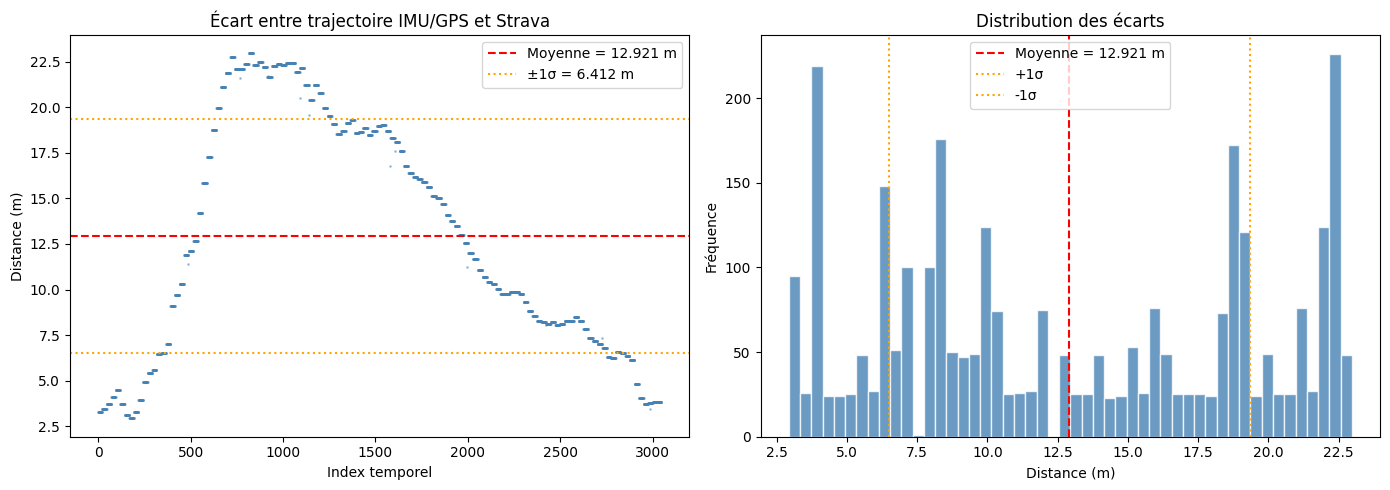

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# --- Statistiques ---
moyenne = df_merged['distance'].mean()
ecart_type = df_merged['distance'].std()
mediane = df_merged['distance'].median()

print("=== Analyse de l'erreur de distance ===")
print(f"Moyenne     : {moyenne:.4f} m")
print(f"Écart-type  : {ecart_type:.4f} m")
print(f"Médiane     : {mediane:.4f} m")
print(f"Min         : {df_merged['distance'].min():.4f} m")
print(f"Max         : {df_merged['distance'].max():.4f} m")

# --- Nuage de points ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Nuage de points : distance en fonction du temps
axes[0].scatter(range(len(df_merged)), df_merged['distance'], 
                s=1, alpha=0.4, color='steelblue')
axes[0].axhline(moyenne, color='red', linestyle='--', label=f'Moyenne = {moyenne:.3f} m')
axes[0].axhline(moyenne + ecart_type, color='orange', linestyle=':', label=f'±1σ = {ecart_type:.3f} m')
axes[0].axhline(moyenne - ecart_type, color='orange', linestyle=':')
axes[0].set_xlabel("Index temporel")
axes[0].set_ylabel("Distance (m)")
axes[0].set_title("Écart entre trajectoire IMU/GPS et Strava")
axes[0].legend()

# Histogramme de la distribution
axes[1].hist(df_merged['distance'], bins=50, color='steelblue', edgecolor='white', alpha=0.8)
axes[1].axvline(moyenne, color='red', linestyle='--', label=f'Moyenne = {moyenne:.3f} m')
axes[1].axvline(moyenne + ecart_type, color='orange', linestyle=':', label=f'+1σ')
axes[1].axvline(moyenne - ecart_type, color='orange', linestyle=':', label=f'-1σ')
axes[1].set_xlabel("Distance (m)")
axes[1].set_ylabel("Fréquence")
axes[1].set_title("Distribution des écarts")
axes[1].legend()
#moyenne géométrique , moyenne géométrique delpacée 

plt.tight_layout()
plt.show()

In [133]:
from scipy import stats
import numpy as np

data = df_merged['distance']
mu, sigma = stats.norm.fit(data)

print(f"Paramètres estimés : μ = {mu:.4f} m, σ = {sigma:.4f} m")

borne_inf = mu - 1.96 * sigma
borne_sup = mu + 1.96 * sigma
pct_dans_intervalle = ((data >= borne_inf) & (data <= borne_sup)).mean() * 100
print(f"\nIC 95% théorique   : [{borne_inf:.2f} m, {borne_sup:.2f} m]")
print(f"% réel dans cet IC : {pct_dans_intervalle:.1f}%  (attendu : 95%)")

print(f"\nSkewness (asymétrie) : {stats.skew(data):.4f}  (0 = parfaitement symétrique)")
print(f"Kurtosis             : {stats.kurtosis(data):.4f}  (0 = normale)")

stat_ks, _ = stats.kstest(data, 'norm', args=(mu, sigma))
print(f"\nStatistique KS : {stat_ks:.4f}  (< 0.05 = écart négligeable en pratique)")

Paramètres estimés : μ = 12.9213 m, σ = 6.4109 m

IC 95% théorique   : [0.36 m, 25.49 m]
% réel dans cet IC : 100.0%  (attendu : 95%)

Skewness (asymétrie) : 0.0875  (0 = parfaitement symétrique)
Kurtosis             : -1.4105  (0 = normale)

Statistique KS : 0.1257  (< 0.05 = écart négligeable en pratique)


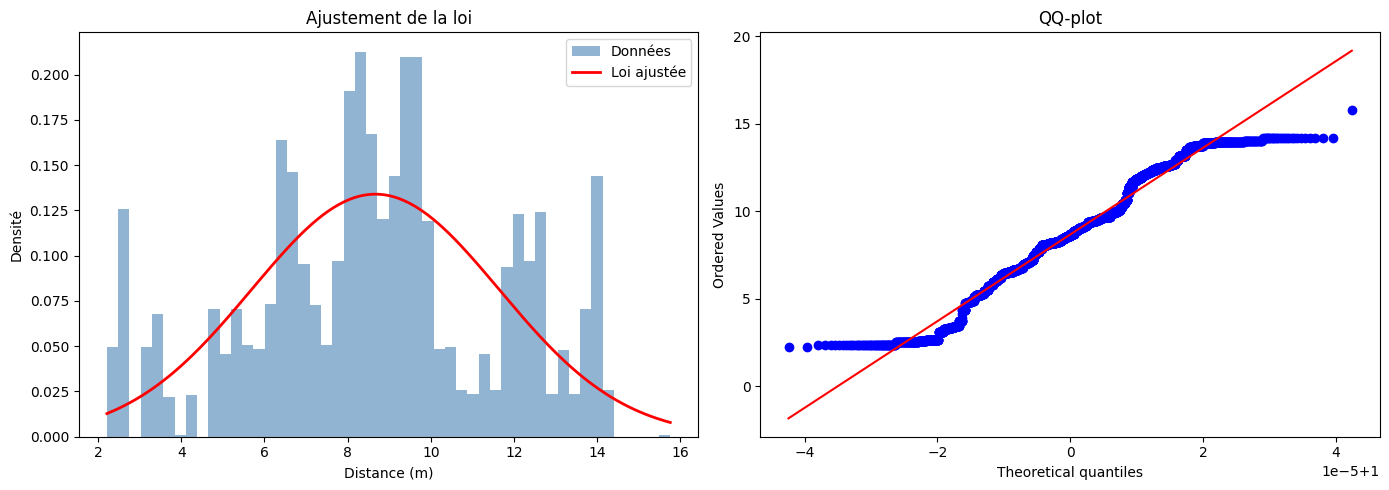

In [98]:
# Supposons que la log-normale est la meilleure (à adapter selon résultats)
meilleure_loi = stats.lognorm
params = meilleure_loi.fit(data)

x = np.linspace(data.min(), data.max(), 200)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogramme + loi ajustée
axes[0].hist(data, bins=50, density=True, alpha=0.6, color='steelblue', label='Données')
axes[0].plot(x, meilleure_loi.pdf(x, *params), 'r-', lw=2, label='Loi ajustée')
axes[0].set_xlabel("Distance (m)")
axes[0].set_ylabel("Densité")
axes[0].set_title("Ajustement de la loi")
axes[0].legend()

stats.probplot(data, dist=meilleure_loi, sparams=params[:-2], plot=axes[1])
axes[1].set_title("QQ-plot")

plt.tight_layout()
plt.show()